# Abstract: The Persistence of Momentum
The momentum effect—the empirical observation that relative performance tends to persist—represents a systematic challenge to the Efficient Market Hypothesis. Since Jegadeesh and Titman (1993), this phenomenon has been established as a universal market feature rather than an anomaly.

Theoretical Framework:

- Empirical Robustness: Cross-asset and cross-jurisdictional replication confirm that price trends are statistically persistent.
- Institutional Exploitation: The continued deployment of momentum strategies by quantitative funds validates the existence of exploitable return premiums in live markets.
- Behavioral Mechanism: The momentum premium arises from delayed information diffusion and investor herding, which facilitate gradual price discovery, contradicting the theory of instantaneous market adjustment.

In [1]:
# Add the project root (one level up from /research) to the path
import sys
import os

sys.path.append(os.path.abspath(os.path.join(os.getcwd(), '..')))

# Libraries needed to run the code
from utils.bybit import BybitConnector
from utils.engine import *
from utils.indicators import *

client = BybitConnector(api_key="", api_secret="", testnet=False)
#price = client.get_ohlcv("BTC/USDT:USDT", "1", 200)
price = client.get_ohlcv("BTC/USDT:USDT", "1", 10000)
price

,timestamp,open,high,low,close,volume
0,2026-06-30 21:41:00,58608.2,58620.6,58608.2,58615.6,3.359
1,2026-06-30 21:42:00,58615.6,58625.9,58615.6,58625.9,2.280
2,2026-06-30 21:43:00,58625.9,58627.0,58588.9,58592.0,22.943
3,2026-06-30 21:44:00,58592.0,58592.1,58548.7,58559.5,80.400
4,2026-06-30 21:45:00,58559.5,58588.5,58558.3,58558.3,6.908
...,...,...,...,...,...,...
995,2026-07-01 14:16:00,59869.9,59938.6,59837.8,59912.7,330.363
996,2026-07-01 14:17:00,59912.7,60049.6,59906.0,60049.5,495.554
997,2026-07-01 14:18:00,60049.5,60057.1,59971.0,60014.4,230.667
998,2026-07-01 14:19:00,60014.4,60014.5,59951.9,59999.9,130.693


# First Step: Proving Market Observation
RSI snapback speed has a strong correlation with MA acceleration.
- If MA acceleration > 0, RSI snapback speed is significantly faster on the long side.
- If MA acceleration < 0, RSI snapback speed is significantly faster on the short side.

| Strong Bull (Force_POS) | Sideway Market | Strong Bear (Force_NEG) |
| :---: | :---: | :---: |
| ![Strong Bull](./image/img_1.png) | ![Stop Trading](./image/img_3.png) | ![Strong Short](./image/img_2.png) |


In [2]:
atr = calculate_atr(price['high'], price['low'], price['close'], 7)
ma, ma_slope, ma_acceleration, rsi = get_market_kinematics(price['close'], atr)

min_len = len(ma)
df = pd.DataFrame({
    'rsi': rsi,
    'ma_slope': ma_slope[-min_len:],
    'acc': ma_acceleration[-min_len:]
})

# 4. Run the Analysis
stats = analyze_regime_speed(df)

# 5. Output Results
print(stats.groupby('regime')['bars_to_neutral'].agg(['mean', 'count', 'std']))

                                mean  count       std
regime                                               
Long_Slope_DOWN_Force_NEG   2.727273     99  2.014327
Long_Slope_DOWN_Force_POS   3.225806     62  2.465628
Long_Slope_UP_Force_NEG     2.684932     73  1.992184
Long_Slope_UP_Force_POS     2.462963     54  1.513623
Short_Slope_DOWN_Force_NEG  3.173913     69  2.162219
Short_Slope_DOWN_Force_POS  2.894737     76  2.306969
Short_Slope_UP_Force_NEG    2.587302     63  1.810676
Short_Slope_UP_Force_POS    3.112500     80  2.056135


The momentum strategy demonstrates efficacy contingent upon a robust regime-detection system, specifically classifying market states as strongly bullish, sideways, or strongly bearish. The lack of statistical edge observed in highly efficient markets during generic testing—where mean recovery times converge toward 3 bar—highlights the necessity of regime-specific analysis.

However, a quantifiable edge emerges when confirming the confluence of MA slope and kinetic force (acceleration), as evidenced in the following comparative analysis.

![Prove](./image/img_4.png)

This alignment minimizes recovery variance, suggesting that RSI mean reversion is structurally optimized when directional bias and kinetic velocity are synchronized.

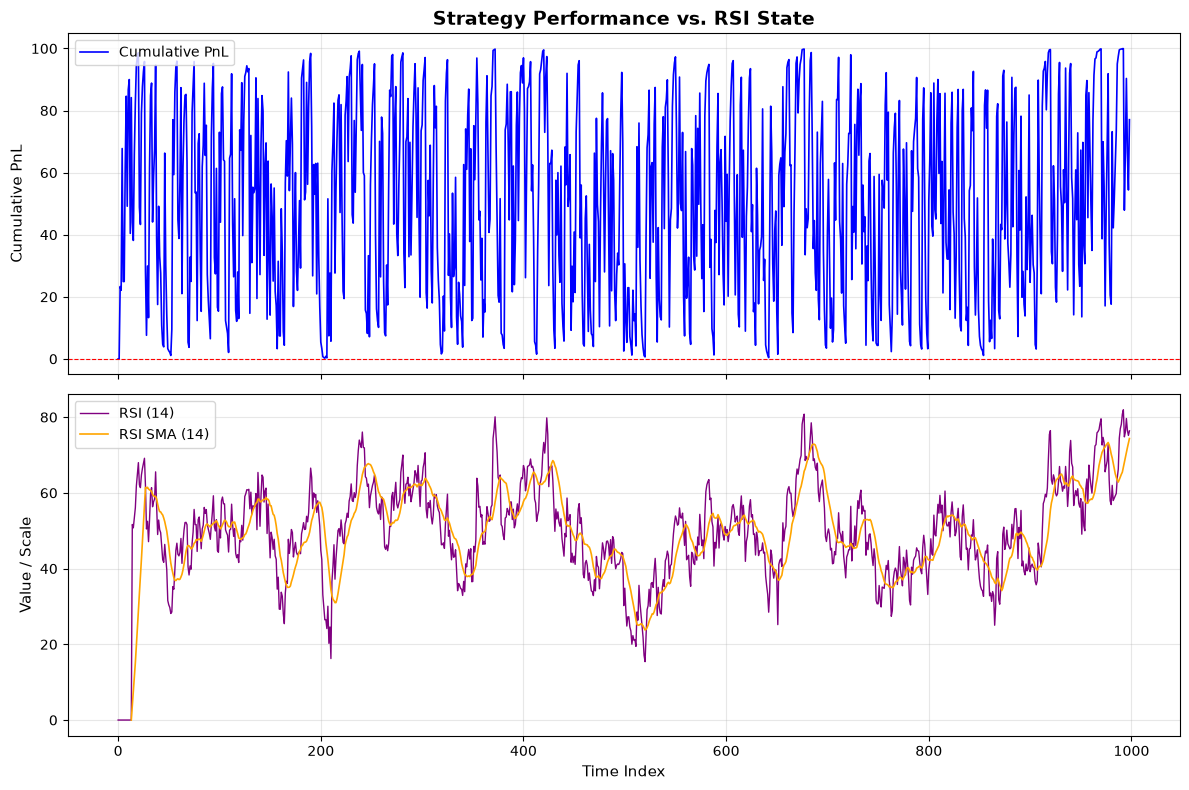

In [11]:
price_clean = np.asanyarray(price['close'], dtype=float)
rsi_2 = get_wilders_rsi(np.diff(price_clean), 2)
rsi_14 = get_wilders_rsi(np.diff(price_clean), 14)
rsi_14_sma = sma(rsi_14, 14)

# Call it with your variables, explicitly passing labels so the chart is clear
plot_two(
    primary_data=rsi_2, 
    secondary_data_1=rsi_14, 
    secondary_data_2=rsi_14_sma,
    primary_label="Cumulative PnL",
    secondary_label_1="RSI (14)",
    secondary_label_2="RSI SMA (14)",
    title="Strategy Performance vs. RSI State"
)

# Assuming your RSI functions return simple lists/arrays:
# Trim them to match the tail of your dataframe if the calculation 
# produced extra elements
df['rsi_14'] = rsi_14[-len(df):]
df['sma_14'] = rsi_14_sma[-len(df):]

## Normalizing the Data
Turning it to machine learning trainable database, where this is our approach.
- Create classifier to identify when a 'block' is about to end.
- Identify using range of machine learning variables to predict if confidence level for block failure is high.

# Conclusion
We do not reject the null hypothesis (lb_pval streak_duration > 0.05). There is insufficient statistical evidence to prove that streak duration is autocorrelated.

We reject the null hypothesis (lb_val rsi, 0.0 < 0.05). There is sufficient statistical evidence to prove that RSi is autocorrelated.

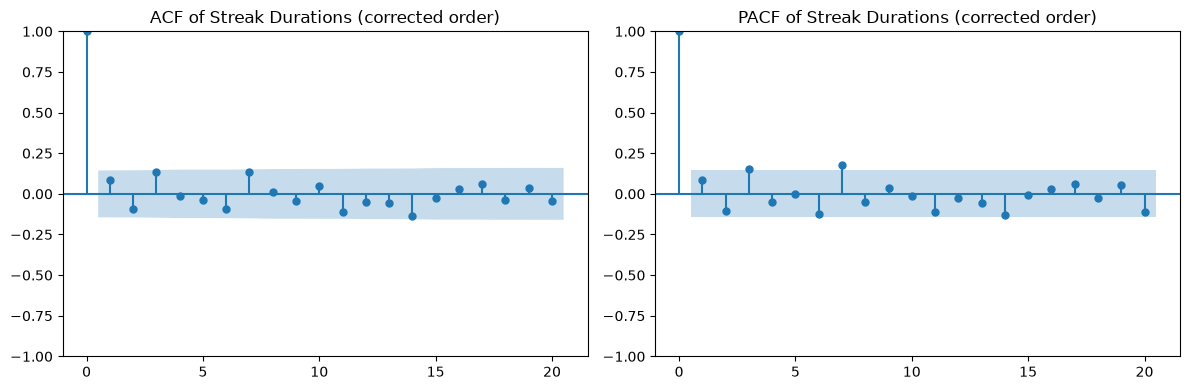

      lb_stat  lb_pvalue
5    6.899241   0.228242
10  13.071808   0.219685
20  22.755919   0.300938
Above SMA (n=93):
     lb_stat  lb_pvalue
10  7.732369    0.65496

Below SMA (n=92):
      lb_stat  lb_pvalue
10  11.029158   0.355251



c:\Users\Himaska\Documents\Projects\Trading_Projects\intraday-momentum-composite\venv\Lib\site-packages\statsmodels\tsa\statespace\sarimax.py:966: UserWarning: Non-stationary starting autoregressive parameters found. Using zeros as starting parameters.
  warn('Non-stationary starting autoregressive parameters'
c:\Users\Himaska\Documents\Projects\Trading_Projects\intraday-momentum-composite\venv\Lib\site-packages\statsmodels\tsa\statespace\sarimax.py:978: UserWarning: Non-invertible starting MA parameters found. Using zeros as starting parameters.
  warn('Non-invertible starting MA parameters found.'
c:\Users\Himaska\Documents\Projects\Trading_Projects\intraday-momentum-composite\venv\Lib\site-packages\statsmodels\base\model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "


Best order by AIC: (2, 0, 2) (AIC=419.10)
                               SARIMAX Results                                
Dep. Variable:                      y   No. Observations:                  185
Model:                 ARIMA(2, 0, 2)   Log Likelihood                -203.552
Date:                Wed, 01 Jul 2026   AIC                            419.105
Time:                        22:54:04   BIC                            438.427
Sample:                             0   HQIC                           426.935
                                - 185                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const          1.4876      0.012    124.232      0.000       1.464       1.511
ar.L1          0.1512      0.108      1.396      0.163      -0.061       0.363
ar.L2     

c:\Users\Himaska\Documents\Projects\Trading_Projects\intraday-momentum-composite\venv\Lib\site-packages\statsmodels\base\model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "


In [38]:
df['rsi_above_sma'] = df['rsi_14'] > df['sma_14']
df['block'] = (df['rsi_above_sma'] != df['rsi_above_sma'].shift()).cumsum()

streak_durations = (
    df.groupby('block')
      .agg(duration=('rsi_above_sma', 'size'),
           is_above=('rsi_above_sma', 'first'))
      .reset_index(drop=True)
)

from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.stats.diagnostic import acorr_ljungbox
import matplotlib.pyplot as plt

durations = streak_durations['duration']

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
plot_acf(durations, lags=20, ax=ax[0]); ax[0].set_title("ACF of Streak Durations (corrected order)")
plot_pacf(durations, lags=20, ax=ax[1]); ax[1].set_title("PACF of Streak Durations (corrected order)")
plt.tight_layout(); plt.show()

lb_test = acorr_ljungbox(durations, lags=[5, 10, 20], return_df=True)
print(lb_test)

# check separately — up-streaks and down-streaks may have different persistence
for flag, label in [(True, 'Above SMA'), (False, 'Below SMA')]:
    sub = streak_durations.loc[streak_durations['is_above'] == flag, 'duration']
    print(f"{label} (n={len(sub)}):\n{acorr_ljungbox(sub, lags=[10], return_df=True)}\n")

import numpy as np
from statsmodels.tsa.arima.model import ARIMA
import itertools

y = np.log1p(durations.values)  # log(1 + duration), used consistently from here on

best_aic, best_order = np.inf, None
for p, d, q in itertools.product(range(4), [0], range(3)):
    try:
        fit = ARIMA(y, order=(p, d, q)).fit()
        if fit.aic < best_aic:
            best_aic, best_order = fit.aic, (p, d, q)
    except Exception:
        continue

print(f"Best order by AIC: {best_order} (AIC={best_aic:.2f})")

model_fit = ARIMA(y, order=best_order).fit()
print(model_fit.summary())

# Ljung-Box on RESIDUALS this time — you want p > 0.05 here (white noise = good fit)
print(acorr_ljungbox(model_fit.resid, lags=[10], return_df=True))

# Using ARIMA to solve for Autocorrelation
The best model used to model the RSI streak is ARIMA.
- Model could still fail as ARIMA assumes the autocorrelation and variance of RSI streak is a constant.

In [34]:
n = len(y)
min_train = int(n * 0.5)
refit_every = 5   # refit every 5 streaks (full refit every step is slow); update in between

preds_log, actual_log = [], []
fitted_model = None
order = best_order

for i in range(min_train, n):
    if fitted_model is None or (i - min_train) % refit_every == 0:
        fitted_model = ARIMA(y[:i], order=order).fit()
    else:
        fitted_model = fitted_model.append([y[i-1]], refit=False)  # fast Kalman-filter update
    preds_log.append(fitted_model.forecast(steps=1)[0])
    actual_log.append(y[i])

preds = np.expm1(np.array(preds_log))
actual = np.expm1(np.array(actual_log))

c:\Users\Himaska\Documents\Projects\Trading_Projects\intraday-momentum-composite\venv\Lib\site-packages\statsmodels\tsa\statespace\sarimax.py:966: UserWarning: Non-stationary starting autoregressive parameters found. Using zeros as starting parameters.
  warn('Non-stationary starting autoregressive parameters'
c:\Users\Himaska\Documents\Projects\Trading_Projects\intraday-momentum-composite\venv\Lib\site-packages\statsmodels\tsa\statespace\sarimax.py:978: UserWarning: Non-invertible starting MA parameters found. Using zeros as starting parameters.
  warn('Non-invertible starting MA parameters found.'
c:\Users\Himaska\Documents\Projects\Trading_Projects\intraday-momentum-composite\venv\Lib\site-packages\statsmodels\base\model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "
c:\Users\Himaska\Documents\Projects\Trading_Projects\intraday-momentum-composite\venv\Lib\site-packages\sta

ARIMA        MAE: 3.62 bars | RMSE: 5.74
Naive(prev)  MAE: 5.33 bars
Naive(mean)  MAE: 3.67 bars
Directional accuracy: 71.0%  (50% = coin flip)


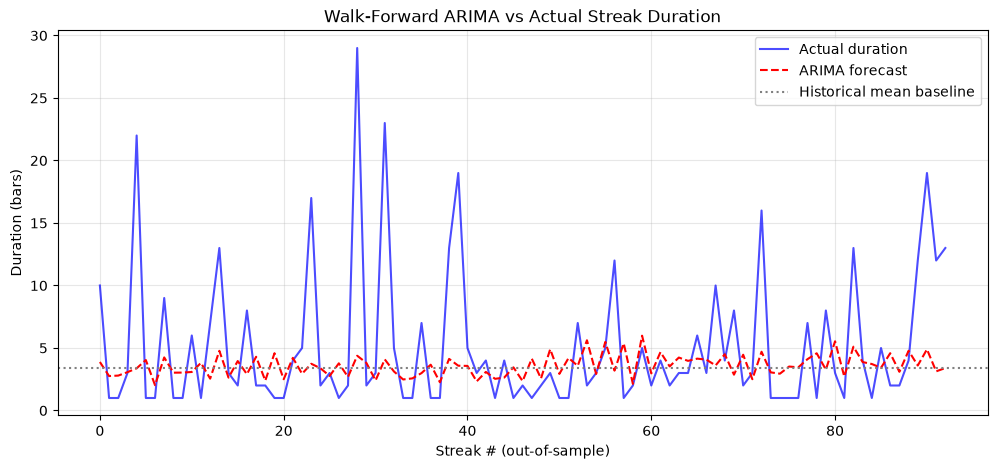

In [35]:
from sklearn.metrics import mean_absolute_error, mean_squared_error

mae_arima = mean_absolute_error(actual, preds)
rmse_arima = np.sqrt(mean_squared_error(actual, preds))

naive_prev = np.expm1(y[min_train-1:n-1])                          # "next streak = last streak"
naive_mean = np.full_like(actual, np.expm1(y[:min_train].mean()))  # "next streak = historical average"

print(f"ARIMA        MAE: {mae_arima:.2f} bars | RMSE: {rmse_arima:.2f}")
print(f"Naive(prev)  MAE: {mean_absolute_error(actual, naive_prev):.2f} bars")
print(f"Naive(mean)  MAE: {mean_absolute_error(actual, naive_mean):.2f} bars")

# directional accuracy: does it correctly call "longer" vs "shorter" than the previous streak?
direction_actual = actual > naive_prev
direction_pred = preds > naive_prev
print(f"Directional accuracy: {(direction_actual == direction_pred).mean():.1%}  (50% = coin flip)")

plt.figure(figsize=(12, 5))
plt.plot(actual, label='Actual duration', color='blue', alpha=0.7)
plt.plot(preds, label='ARIMA forecast', color='red', linestyle='--')
plt.axhline(np.expm1(y[:min_train].mean()), color='gray', linestyle=':', label='Historical mean baseline')
plt.title("Walk-Forward ARIMA vs Actual Streak Duration")
plt.xlabel("Streak # (out-of-sample)"); plt.ylabel("Duration (bars)")
plt.legend(); plt.grid(True, alpha=0.3); plt.show()

In [ ]:
from scipy.stats import binomtest

n_test = len(preds)
base_rate = direction_actual.mean()  # how often "longer than previous" actually happened
majority_baseline_acc = max(base_rate, 1 - base_rate)  # accuracy of "always guess the majority class"

print(f"Out-of-sample streaks tested: {n_test}")
print(f"Base rate (actual longer than prev): {base_rate:.1%}")
print(f"Majority-class baseline accuracy:    {majority_baseline_acc:.1%}")

# Is 71% significantly better than a coin flip, given this sample size
n_correct = int(round(0.71 * n_test))
test_vs_chance = binomtest(n_correct, n_test, 0.5, alternative='greater')
test_vs_majority = binomtest(n_correct, n_test, majority_baseline_acc, alternative='greater')

print(f"p-value vs 50% chance:            {test_vs_chance.pvalue:.4f}")
print(f"p-value vs majority-class guess:  {test_vs_majority.pvalue:.4f}")

# Final confirmation.

Out-of-sample streaks tested: 93
Base rate (actual longer than prev): 48.4%
Majority-class baseline accuracy:    51.6%
p-value vs 50% chance:            0.0000
p-value vs majority-class guess:  0.0001
